# Retail Sales Forecasting & Replenishment

**Objective:** explore two years of daily store/SKU sales, clean data, engineer time features, compare forecasting/regression models, evaluate category errors, and recommend reorder quantities.

> All data is synthetic and generated for this project. Run cells from top to bottom.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from retail_pipeline import clean_data, add_features, evaluate, run

raw = pd.read_csv(ROOT / "data" / "retail_daily_sales_raw.csv")
print("Raw shape:", raw.shape)
raw.head()


Raw shape: (23392, 13)


,date,store_id,product_id,category,product_name,unit_price,discount_pct,promotion,stock_received,stock_available,units_sold,ending_stock,stockout
0,2024-01-01,ST001,P001,Beverages,Sparkling Water,35.0,0.0,0,73,218,23.0,195,0
1,2024-01-02,ST001,P001,Beverages,Sparkling Water,35.0,0.0,0,0,195,25.0,170,0
2,2024-01-03,ST001,P001,Beverages,Sparkling Water,35.0,0.0,0,0,170,29.0,141,0
3,2024-01-04,ST001,P001,Beverages,Sparkling Water,35.0,0.0,0,0,141,18.0,123,0
4,2024-01-05,ST001,P001,Beverages,Sparkling Water,35.0,0.0,0,0,123,25.0,98,0


## 1. Data quality checks

In [2]:
display(raw.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", raw.duplicated().sum())
print("Negative sales:", (raw["units_sold"] < 0).sum())
print("Date range:", raw["date"].min(), "to", raw["date"].max())


,missing_values
date,0
store_id,0
product_id,0
category,0
product_name,0
unit_price,20
discount_pct,0
promotion,0
stock_received,0
stock_available,0


Duplicate rows: 0
Negative sales: 10
Date range: 2024-01-01 to 2025-12-31


In [3]:
data = clean_data(raw)
print("Clean shape:", data.shape)
display(data.describe(include="all").T)


Clean shape: (23392, 13)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,23392,NaN,NaN,NaN,2024-12-31 00:00:00,2024-01-01 00:00:00,2024-07-01 00:00:00,2024-12-31 00:00:00,2025-07-02 00:00:00,2025-12-31 00:00:00,NaN
store_id,23392,4,ST001,5848,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,23392,8,P001,2924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,23392,4,Beverages,5848,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,23392,8,Sparkling Water,2924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_price,23392.0,NaN,NaN,NaN,78.139475,16.0,37.55,57.5,96.25,180.0,49.052631
discount_pct,23392.0,NaN,NaN,NaN,0.013007,0.0,0.0,0.0,0.0,0.2,0.042103
promotion,23392.0,NaN,NaN,NaN,0.104993,0.0,0.0,0.0,0.0,1.0,0.306551
stock_received,23392.0,NaN,NaN,NaN,6.59717,0.0,0.0,0.0,0.0,99.0,21.24821
stock_available,23392.0,NaN,NaN,NaN,19.959516,0.0,0.0,0.0,30.0,326.0,37.210062


## 2. Exploratory data analysis

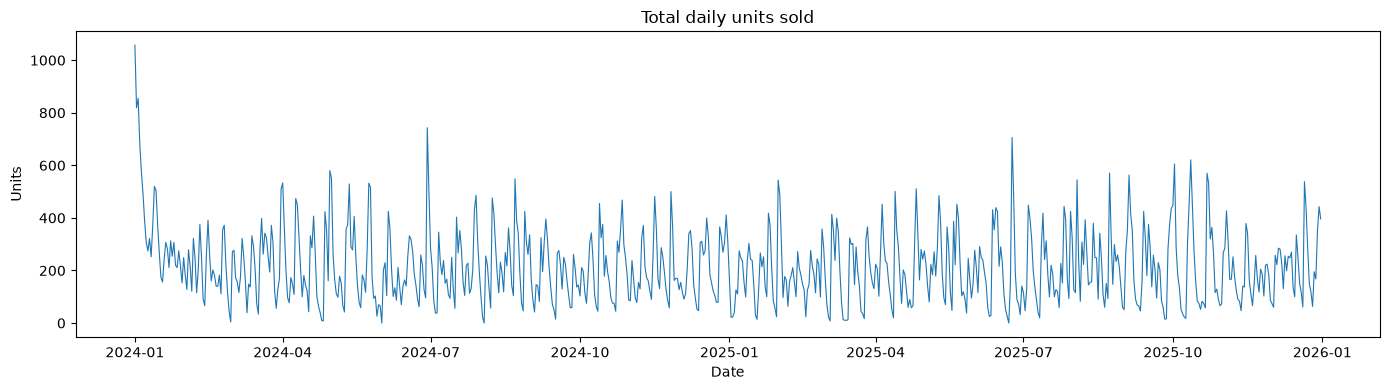

In [4]:
daily = data.groupby("date", as_index=False)["units_sold"].sum()
plt.figure(figsize=(14,4))
plt.plot(pd.to_datetime(daily["date"]), daily["units_sold"], linewidth=0.8)
plt.title("Total daily units sold")
plt.xlabel("Date"); plt.ylabel("Units"); plt.tight_layout(); plt.show()


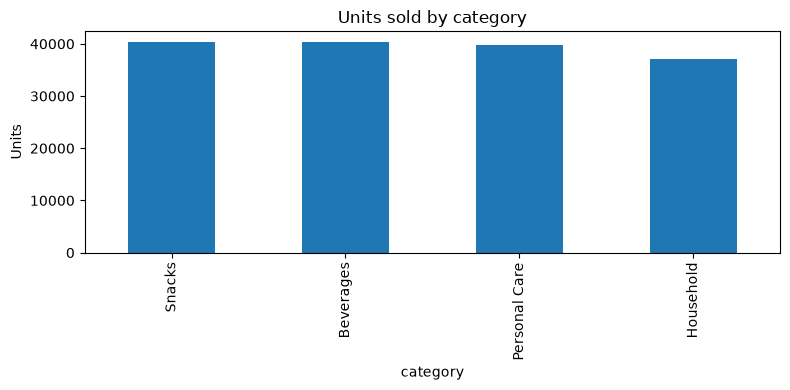

In [5]:
category_sales = data.groupby("category")["units_sold"].sum().sort_values(ascending=False)
category_sales.plot(kind="bar", figsize=(8,4), title="Units sold by category")
plt.ylabel("Units"); plt.tight_layout(); plt.show()


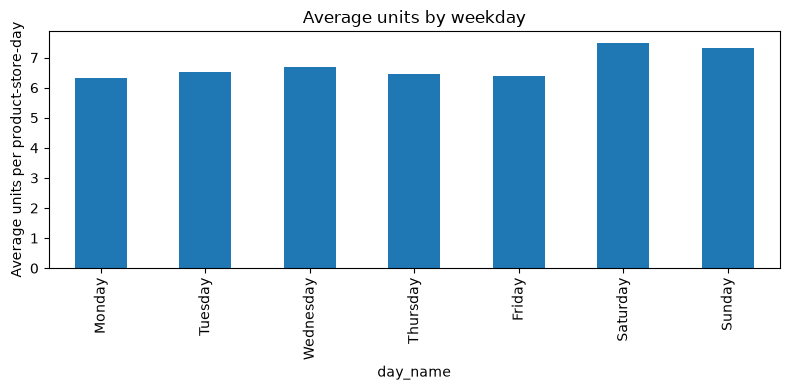

In [6]:
dow = data.assign(day_name=pd.to_datetime(data["date"]).dt.day_name()).groupby("day_name")["units_sold"].mean()
dow = dow.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
dow.plot(kind="bar", figsize=(8,4), title="Average units by weekday")
plt.ylabel("Average units per product-store-day"); plt.tight_layout(); plt.show()


## 3. Feature engineering

In [7]:
featured = add_features(data)
feature_cols = ["unit_price","discount_pct","promotion","day_of_week","day_of_month","month",
                "week_of_year","is_weekend","day_of_year_sin","day_of_year_cos",
                "sales_lag_1","sales_lag_7","sales_lag_14","sales_lag_28",
                "sales_roll_mean_7","sales_roll_mean_28"]
display(featured[["date","store_id","product_id","units_sold"] + feature_cols].tail())


,date,store_id,product_id,units_sold,unit_price,discount_pct,promotion,day_of_week,day_of_month,month,week_of_year,is_weekend,day_of_year_sin,day_of_year_cos,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_roll_mean_7,sales_roll_mean_28
23387,2025-12-27,ST004,P008,0,45.6,0.05,1,5,27,12,52,1,-0.073045,0.997329,0.0,15.0,18.0,0.0,14.428571,12.750000
23388,2025-12-28,ST004,P008,0,48.0,0.00,0,6,28,12,52,1,-0.055879,0.998438,0.0,19.0,18.0,0.0,12.285714,12.750000
23389,2025-12-29,ST004,P008,23,48.0,0.00,0,0,29,12,1,0,-0.038696,0.999251,0.0,25.0,19.0,0.0,9.571429,12.750000
23390,2025-12-30,ST004,P008,26,40.8,0.15,1,1,30,12,1,0,-0.021501,0.999769,23.0,21.0,27.0,0.0,9.285714,13.571429
23391,2025-12-31,ST004,P008,3,48.0,0.00,0,2,31,12,1,0,-0.004301,0.999991,26.0,21.0,17.0,0.0,10.000000,14.500000


## 4. Train, compare, evaluate, forecast and recommend

In [11]:
comparison, category_metrics, future, reorder = run(
    ROOT / "data" / "retail_daily_sales_raw.csv",
    output_dir=ROOT / "outputs",
    report_dir=ROOT / "reports"
)
display(comparison)
display(category_metrics)
display(future.head(10))
display(reorder.head(10))


,Model,MAE,RMSE,WAPE,Bias
0,Seasonal naive (7-day lag),9.522418,15.568288,1.423552,-0.156929
1,Random Forest baseline,5.175808,8.452596,0.773756,-0.012619
2,Random Forest tuned,5.133843,8.362860,0.767483,0.004589


,category,MAE,RMSE,WAPE,Bias
1,Household,4.426442,7.138394,0.748934,0.501247
3,Snacks,4.804921,7.655121,0.729912,0.187661
2,Personal Care,5.348489,8.433858,0.795250,-0.092796
0,Beverages,5.955518,9.953001,0.790062,-0.577758


,date,store_id,product_id,category,product_name,forecast_units
0,2026-01-01,ST001,P001,Beverages,Sparkling Water,27.35
1,2026-01-02,ST001,P001,Beverages,Sparkling Water,15.18
2,2026-01-03,ST001,P001,Beverages,Sparkling Water,13.39
3,2026-01-04,ST001,P001,Beverages,Sparkling Water,8.22
4,2026-01-05,ST001,P001,Beverages,Sparkling Water,2.93
5,2026-01-06,ST001,P001,Beverages,Sparkling Water,2.35
6,2026-01-07,ST001,P001,Beverages,Sparkling Water,2.05
7,2026-01-01,ST001,P002,Beverages,Orange Juice,11.64
8,2026-01-02,ST001,P002,Beverages,Orange Juice,9.46
9,2026-01-03,ST001,P002,Beverages,Orange Juice,9.14


,store_id,product_id,ending_stock,category,product_name,forecast_7d,safety_stock,recommended_reorder_qty
0,ST001,P001,60,Beverages,Sparkling Water,71.47,15.0,27
1,ST001,P002,106,Beverages,Orange Juice,66.02,14.0,0
2,ST001,P003,123,Snacks,Potato Chips,37.35,8.0,0
3,ST001,P004,0,Snacks,Granola Bars,19.16,4.0,24
4,ST001,P005,111,Household,Laundry Detergent,38.18,8.0,0
5,ST001,P006,20,Household,Paper Towels,32.21,7.0,20
6,ST001,P007,0,Personal Care,Shampoo,15.37,4.0,20
7,ST001,P008,14,Personal Care,Toothpaste,51.60,11.0,49
8,ST002,P001,7,Beverages,Sparkling Water,64.52,13.0,71
9,ST002,P002,0,Beverages,Orange Juice,16.84,4.0,21


## 5. Limitations and responsible use

- The dataset is synthetic; metrics do not represent a real retailer.
- Sales are not identical to unconstrained demand. Stockouts censor demand and can bias training labels downward.
- The feature set omits weather, local events, competitor pricing, holidays beyond the generated pattern, returns and supplier constraints.
- Seven-day reorder calculations assume a 7-day lead time and a 20% buffer; actual lead times and service-level targets should replace these assumptions.
- The recursive 7-day forecast can accumulate error. Retrain and monitor with real chronological backtests before operational use.
